<a href="https://colab.research.google.com/github/rodrigoesborges/conju-python/blob/main/GRUPO%204%20tabelas%20(politica%20monet%C3%A1ria)%20meta%20de%20infla%C3%A7%C3%A3o.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [32]:
!pip install -q python-bcb ipeadatapy

In [34]:
import time
import pandas as pd
import numpy as np
from bcb import sgs
import ipeadatapy

def baixar_bcb_seguro(codigos, inicio='1999-01-01', tentativas=5):
    for i in range(tentativas):
        try:
            return sgs.get(codigos, start=inicio)
        except Exception:
            print(f"Oscilação na API do BCB. Tentando novamente ({i+1}/{tentativas})...")
            time.sleep(2)
    raise RuntimeError("Não foi possível baixar os dados do BCB após várias tentativas.")

# ==============================================================================
# 0) OBTENÇÃO VIA APIs COM PADRONIZAÇÃO DE DATAS (1999-01-01 até hoje)
# ==============================================================================
# 0.1) BCB: Meta de Inflação (13521) e IGP-M % mensal (189)
metadeinflacao = baixar_bcb_seguro([13521, 189], inicio='1999-01-01').ffill()
df_bcb = metadeinflacao.reset_index().rename(columns={
    '13521': 'Meta de Inflacao',
    '189': 'IGP-M'
})
# Normaliza sempre para o dia 01 do mês
df_bcb['Date'] = pd.to_datetime(df_bcb['Date']).dt.to_period('M').dt.to_timestamp()
df_bcb['periodo'] = df_bcb['Date'].dt.strftime('%Y%m%d').astype(int)

base_bcb = df_bcb.melt(
    id_vars=['periodo', 'Date'],
    value_vars=['Meta de Inflacao', 'IGP-M'],
    var_name='indicador',
    value_name='valor'
)

# 0.2) Ipeadata: IGP12_IGPM12 (Número-índice)
igp = ipeadatapy.timeseries("IGP12_IGPM12").reset_index()
igp.columns = igp.columns.str.strip()
igp = igp.rename(columns={
    "DATE": "Date",
    "CODE": "indicador",
    "VALUE (-)": "valor"
})
# Normaliza sempre para o dia 01 do mês e aplica o mesmo recorte (>= 1999-01-01)
igp["Date"] = pd.to_datetime(igp["Date"]).dt.to_period('M').dt.to_timestamp()
igp["periodo"] = igp["Date"].dt.strftime("%Y%m%d").astype(int)
base_ipea = igp[igp["Date"] >= "1999-01-01"][["periodo", "Date", "indicador", "valor"]]

# ==============================================================================
# 1) TABELA BASE UNIFICADA EM FORMATO LONGO (PERÍODOS ALINHADOS)
# ==============================================================================
periodos_comuns = set(base_bcb['periodo']).intersection(set(base_ipea['periodo']))

tabela_base = (
    pd.concat([base_bcb, base_ipea], ignore_index=True)
    .query("periodo in @periodos_comuns")
    .dropna(subset=['valor'])
    .sort_values(['indicador', 'periodo'])
    .reset_index(drop=True)
)

print(f"Período total da base: {tabela_base['periodo'].min()} até {tabela_base['periodo'].max()}")
print(f"Período total da base: {tabela_base['periodo'].min()} até {tabela_base['periodo'].max()}")

# Exibe os últimos 5 meses de CADA série separadamente
for ind in ['Meta de Inflacao', 'IGP-M', 'IGP12_IGPM12']:
    print(f"\n--- TABELA BASE: {ind} (últimos 5 meses) ---")
    display(tabela_base[tabela_base['indicador'] == ind][['periodo', 'indicador', 'valor']].tail(5))


Período total da base: 19990101 até 20261001
Período total da base: 19990101 até 20261001

--- TABELA BASE: Meta de Inflacao (últimos 5 meses) ---


,periodo,indicador,valor
997,20260601,Meta de Inflacao,3.0
998,20260701,Meta de Inflacao,3.0
999,20260801,Meta de Inflacao,3.0
1000,20260901,Meta de Inflacao,3.0
1001,20261001,Meta de Inflacao,3.0



--- TABELA BASE: IGP-M (últimos 5 meses) ---


,periodo,indicador,valor
329,20260601,IGP-M,-0.50
330,20260701,IGP-M,-1.16
331,20260801,IGP-M,-0.22
332,20260901,IGP-M,1.57
333,20261001,IGP-M,1.47



--- TABELA BASE: IGP12_IGPM12 (últimos 5 meses) ---


,periodo,indicador,valor
663,20260601,IGP12_IGPM12,1223.761
664,20260701,IGP12_IGPM12,1209.617
665,20260801,IGP12_IGPM12,1206.897
666,20260901,IGP12_IGPM12,1225.846
667,20261001,IGP12_IGPM12,1243.905


In [31]:
# ==============================================================================
# 2) FUNÇÕES PARA ACUMULADO NO ANO E ACUMULADO EM 12 MESES
# ==============================================================================
# Diferenciação conforme natureza da série:
# - 'IGP-M': variação % mensal -> 'taxa' (juros compostos)
# - 'Meta de Inflacao': meta anual vigente -> 'estoque' (nível)
# - 'IGP12_IGPM12': número-índice (Ipeadata) -> 'estoque' (nível)
config_series = {
    'IGP-M': {'tipo': 'taxa', 'freq': 'mensal'},
    'Meta de Inflacao': {'tipo': 'estoque', 'freq': 'mensal'},
    'IGP12_IGPM12': {'tipo': 'estoque', 'freq': 'mensal'}
}

def acumulado_ano(df, config):
    df_calc = df.sort_values(['indicador', 'Date']).copy()
    df_calc['ano'] = df_calc['Date'].dt.year
    resultados = []

    for ind, grupo in df_calc.groupby('indicador', sort=False):
        tipo = config[ind]['tipo']
        g = grupo.copy()

        if tipo == 'taxa':
            g['fator'] = 1 + (g['valor'] / 100.0)
            g['valor_acum'] = (g.groupby('ano')['fator'].cumprod() - 1) * 100.0
        elif tipo == 'fluxo':
            g['valor_acum'] = g.groupby('ano')['valor'].cumsum()
        elif tipo == 'estoque':
            g['valor_acum'] = g['valor']

        resultados.append(g[['periodo', 'Date', 'indicador', 'valor_acum']].rename(columns={'valor_acum': 'valor'}))

    return pd.concat(resultados, ignore_index=True)


def acumulado_12m(df, config):
    df_calc = df.sort_values(['indicador', 'Date']).copy()
    resultados = []

    for ind, grupo in df_calc.groupby('indicador', sort=False):
        tipo = config[ind]['tipo']
        freq = config[ind]['freq']
        janela = 12 if freq == 'mensal' else 4
        g = grupo.copy()

        if tipo == 'taxa':
            g['fator'] = 1 + (g['valor'] / 100.0)
            g['valor_12m'] = (
                g['fator']
                .rolling(window=janela, min_periods=janela)
                .apply(np.prod, raw=True) - 1
            ) * 100.0
        elif tipo == 'fluxo':
            g['valor_12m'] = g['valor'].rolling(window=janela, min_periods=janela).sum()
        elif tipo == 'estoque':
            g['valor_12m'] = g['valor']

        resultados.append(g[['periodo', 'Date', 'indicador', 'valor_12m']].rename(columns={'valor_12m': 'valor'}))

    return pd.concat(resultados, ignore_index=True)

In [29]:
# ==============================================================================
# 3) APLICAÇÃO DAS FUNÇÕES -> TABELAS INTERMEDIÁRIAS (SEPARADAS POR SÉRIE)
# ==============================================================================
series = ['Meta de Inflacao', 'IGP-M', 'IGP12_IGPM12']

# --- TABELA INTERMEDIÁRIA 1: Acumulado no ano ---
tabela_intermediaria_1 = (
    acumulado_ano(tabela_base, config_series)
    .sort_values(['indicador', 'periodo'])
    .reset_index(drop=True)
)
print(f"=== 3.1) TABELA INTERMEDIÁRIA 1 (Acumulado no Ano) ===")
for ind in series:
    print(f"\n--- {ind} ---")
    display(tabela_intermediaria_1[tabela_intermediaria_1['indicador'] == ind][['periodo', 'indicador', 'valor']].tail(4))


# --- TABELA INTERMEDIÁRIA 2: Acumulado em 12 meses ---
tabela_intermediaria_2 = (
    acumulado_12m(tabela_base, config_series)
    .dropna(subset=['valor'])
    .sort_values(['indicador', 'periodo'])
    .reset_index(drop=True)
)
print(f"\n=== 3.2) TABELA INTERMEDIÁRIA 2 (Acumulado em 12 Meses) ===")
for ind in series:
    print(f"\n--- {ind} ---")
    display(tabela_intermediaria_2[tabela_intermediaria_2['indicador'] == ind][['periodo', 'indicador', 'valor']].tail(4))


# --- TABELA INTERMEDIÁRIA 3: Var. do Acumulado no ano vs 12 meses antes ---
t3 = tabela_intermediaria_1[['periodo', 'Date', 'indicador', 'valor']].copy()
t3['periodo_anterior'] = (t3['Date'] - pd.DateOffset(years=1)).dt.strftime('%Y%m%d').astype(int)

tabela_intermediaria_3 = pd.merge(
    t3,
    t3[['periodo', 'indicador', 'valor']],
    left_on=['indicador', 'periodo_anterior'],
    right_on=['indicador', 'periodo'],
    suffixes=('', '.y')
)

tabela_intermediaria_3['var_acum_ano'] = (tabela_intermediaria_3['valor'] / tabela_intermediaria_3['valor.y']) - 1
tabela_intermediaria_3 = (
    tabela_intermediaria_3[['periodo', 'periodo_anterior', 'indicador', 'valor', 'valor.y', 'var_acum_ano']]
    .sort_values(['indicador', 'periodo'])
    .reset_index(drop=True)
)

print(f"\n=== 3.3) TABELA INTERMEDIÁRIA 3 (Var. Acum. Ano vs 12m antes) ===")
for ind in series:
    print(f"\n--- {ind} ---")
    display(tabela_intermediaria_3[tabela_intermediaria_3['indicador'] == ind].tail(4))


# --- TABELA INTERMEDIÁRIA 4: Var. de 12 meses vs 12 meses anteriores ---
t4 = tabela_intermediaria_2[['periodo', 'Date', 'indicador', 'valor']].copy()
t4['periodo_anterior'] = (t4['Date'] - pd.DateOffset(years=1)).dt.strftime('%Y%m%d').astype(int)

tabela_intermediaria_4 = pd.merge(
    t4,
    t4[['periodo', 'indicador', 'valor']],
    left_on=['indicador', 'periodo_anterior'],
    right_on=['indicador', 'periodo'],
    suffixes=('', '.y')
)

tabela_intermediaria_4['var_12m'] = (tabela_intermediaria_4['valor'] / tabela_intermediaria_4['valor.y']) - 1
tabela_intermediaria_4 = (
    tabela_intermediaria_4[['periodo', 'periodo_anterior', 'indicador', 'valor', 'valor.y', 'var_12m']]
    .sort_values(['indicador', 'periodo'])
    .reset_index(drop=True)
)

print(f"\n=== 3.4) TABELA INTERMEDIÁRIA 4 (Var. 12m vs 12m anteriores) ===")
for ind in series:
    print(f"\n--- {ind} ---")
    display(tabela_intermediaria_4[tabela_intermediaria_4['indicador'] == ind].tail(4))

=== 3.1) TABELA INTERMEDIÁRIA 1 (Acumulado no Ano) ===

--- Meta de Inflacao ---


,periodo,indicador,valor
998,20260701,Meta de Inflacao,3.0
999,20260801,Meta de Inflacao,3.0
1000,20260901,Meta de Inflacao,3.0
1001,20261001,Meta de Inflacao,3.0



--- IGP-M ---


,periodo,indicador,valor
330,20260701,IGP-M,2.078296
331,20260801,IGP-M,1.853724
332,20260901,IGP-M,3.452827
333,20261001,IGP-M,4.973584



--- IGP12_IGPM12 ---


,periodo,indicador,valor
664,20260701,IGP12_IGPM12,1209.617
665,20260801,IGP12_IGPM12,1206.897
666,20260901,IGP12_IGPM12,1225.846
667,20261001,IGP12_IGPM12,1243.905


... (14 outputs left out)


--- IGP-M ---


,periodo,periodo_anterior,indicador,valor,valor.y,var_12m
307,20260701,20250701,IGP-M,2.772183,2.961368,-0.063884
308,20260801,20250801,IGP-M,2.178243,3.033233,-0.281874
309,20260901,20250901,IGP-M,3.348378,2.828436,0.183827
310,20261001,20251001,IGP-M,5.246487,0.924206,4.676751



--- IGP12_IGPM12 ---


,periodo,periodo_anterior,indicador,valor,valor.y,var_12m
629,20260701,20250701,IGP12_IGPM12,1209.617,1177.168,0.027565
630,20260801,20250801,IGP12_IGPM12,1206.897,1181.369,0.021609
631,20260901,20250901,IGP12_IGPM12,1225.846,1186.283,0.033350
632,20261001,20251001,IGP12_IGPM12,1243.905,1182.005,0.052369


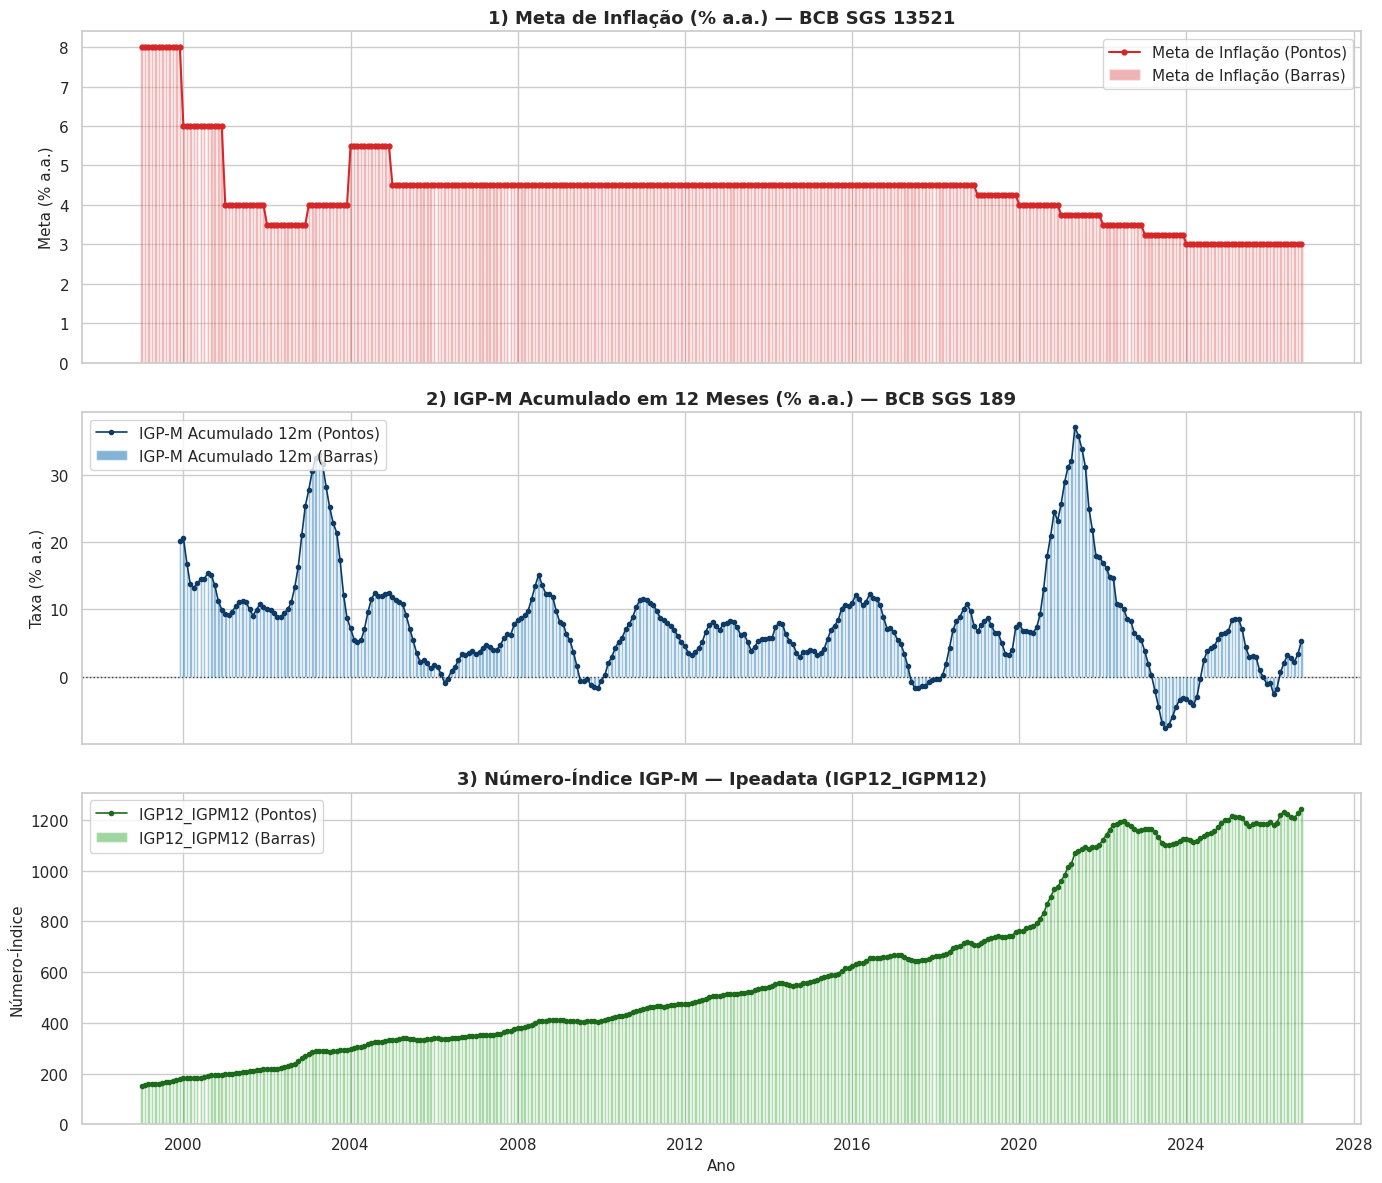

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

# ==============================================================================
# 5) 3 GRÁFICOS SEPARADOS (UM PARA CADA SÉRIE) — COM BARRAS E PONTOS
# ==============================================================================
df_plot = tabela_intermediaria_2.copy()

sns.set_theme(style="whitegrid")
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

# --- Gráfico 1 (Separado): Meta de Inflação (BCB 13521) ---
df_meta = df_plot[df_plot['indicador'] == 'Meta de Inflacao']
ax1.bar(
    df_meta['Date'], df_meta['valor'],
    width=22, color='#d62728', alpha=0.35,
    label='Meta de Inflação (Barras)'
)
ax1.plot(
    df_meta['Date'], df_meta['valor'],
    color='#d62728', linewidth=1.5,
    marker='o', markersize=3.5,
    label='Meta de Inflação (Pontos)'
)
ax1.set_title('1) Meta de Inflação (% a.a.) — BCB SGS 13521', fontsize=13, fontweight='bold')
ax1.set_ylabel('Meta (% a.a.)', fontsize=11)
ax1.legend(loc='upper right')

# --- Gráfico 2 (Separado): IGP-M Acumulado em 12 Meses (BCB 189) ---
df_igpm = df_plot[df_plot['indicador'] == 'IGP-M']
ax2.bar(
    df_igpm['Date'], df_igpm['valor'],
    width=22, color='#1f77b4', alpha=0.55,
    label='IGP-M Acumulado 12m (Barras)'
)
ax2.plot(
    df_igpm['Date'], df_igpm['valor'],
    color='#0d3b66', linewidth=1.2,
    marker='o', markersize=3,
    label='IGP-M Acumulado 12m (Pontos)'
)
ax2.axhline(0, color='black', linestyle=':', linewidth=1, alpha=0.7)
ax2.set_title('2) IGP-M Acumulado em 12 Meses (% a.a.) — BCB SGS 189', fontsize=13, fontweight='bold')
ax2.set_ylabel('Taxa (% a.a.)', fontsize=11)
ax2.legend(loc='upper left')

# --- Gráfico 3 (Separado): Número-Índice IGP12_IGPM12 (Ipeadata) ---
df_indice = df_plot[df_plot['indicador'] == 'IGP12_IGPM12']
ax3.bar(
    df_indice['Date'], df_indice['valor'],
    width=22, color='#2ca02c', alpha=0.45,
    label='IGP12_IGPM12 (Barras)'
)
ax3.plot(
    df_indice['Date'], df_indice['valor'],
    color='#1b6b1b', linewidth=1.2,
    marker='o', markersize=3,
    label='IGP12_IGPM12 (Pontos)'
)
ax3.set_title('3) Número-Índice IGP-M — Ipeadata (IGP12_IGPM12)', fontsize=13, fontweight='bold')
ax3.set_xlabel('Ano', fontsize=11)
ax3.set_ylabel('Número-Índice', fontsize=11)
ax3.legend(loc='upper left')

plt.tight_layout()
plt.show()